# Q2

In `Q1.ipynb`, we observed that the trained GRU $f_\theta$ uses token dependent predictive information and that its predictions exhibit increasingly negative bias on longer, sparser exact count sequences ($K=6$). However, those Q1 sequences were independently sampled at each length, so token arrangements, internal zero gaps, and token density changed simultaneously. Consequently, the observed prediction differences could not be attributed uniquely to additional recurrent transitions or to any specific memory mechanism.

In Q2, we isolate a more precisely controlled transformation: appending $m$ trailing zeros to an otherwise unchanged binary prefix $x_{1:T} \in \{0,1\}^T$.

The experiment is based on an exact mathematical property of the counting function

$$
f^*(x_{1:T}) = \sum_{t=1}^{T} x_t.
$$

For every nonnegative integer $m$,

$$
f^*(x_{1:T}, 0^m) = f^*(x_{1:T}),
$$

where

$$
0^m = (\underbrace{0, 0, \ldots, 0}_{m\text{ times}})
$$

denotes $m$ consecutive zero tokens, and $(x_{1:T}, 0^m) \in \{0,1\}^{T+m}$ denotes their concatenation with the original prefix. Because the appended zeros contribute nothing to the sum, an exact counting function must preserve its output regardless of $m$. This property is termed **zero extension invariance**.

Unlike Q1, pairing each extended sequence $(x_{1:T}, 0^m)$ with its own unextended prefix $x_{1:T}$ holds the original tokens, their order, their internal spacing, and their cumulative count fixed. We can therefore measure the effect of $m$ additional zero-token recurrent transitions on the learned predictor without increasing the target count magnitude or changing the original prefix.

For the trained GRU $f_\theta$, define the paired prediction drift

$$
\Delta_m(x_{1:T}) = f_\theta(x_{1:T}, 0^m) - f_\theta(x_{1:T}).
$$

For a specified distribution over prefixes $X = X_{1:T}$, the primary experimental quantity is the mean absolute prediction drift

$$
D(m) = \mathbb{E}_X\big[|\Delta_m(X)|\big],
$$

supplemented by the mean signed drift

$$
S(m) = \mathbb{E}_X\big[\Delta_m(X)\big].
$$

The first measures the magnitude of prediction non-invariance; the second indicates whether changes are predominantly positive or negative. Because exact prediction preservation is not synonymous with correctness—a model could preserve an inaccurate prefix prediction perfectly—these drift quantities are evaluated alongside accuracy and error relative to the true count $f^*(x_{1:T})$.

This is a behavioural measurement of output preservation, not a direct measurement of information retention within the hidden state. Because the trained readout is affine $\Delta \hat{y} = w_{\mathrm{out}}^\top \Delta h$, hidden state changes can occur without altering the final prediction, and output drift does not by itself prove that previously accumulated count information has been erased from the hidden state.

Although the paired design removes variation in the original prefix, the extended sequences need not follow the original training distribution. In particular, long contiguous zero tails are atypical under independent $\mathrm{Bernoulli}(0.5)$ sampling, and sufficiently large $m$ produces total sequence lengths $T+m$ beyond the training horizon $T \leq 20$.

The learned GRU is not explicitly constrained by its final count MSE objective to satisfy zero-extension invariance. Whether it does so is therefore an empirical question.

### Connection to Q1

In Q1, mean prediction bias became increasingly negative as sequence length increased while the true count remained six. The present experiment investigates whether a similar directional effect occurs when the same prefix is extended with zeros.

For comparison, the pure length-only predictor $f_{\mathrm{length}}(x_{1:T}) = pT$ would exhibit positive drift:

$$
\Delta_m^{\mathrm{length}} = pm.
$$

Negative drift in Q2 would therefore be inconsistent with this simple length-only response. However, it would not uniquely establish memory decay or identify the responsible recurrent mechanism. The magnitude, sign, and dependence of $\Delta_m(x_{1:T})$ on $m$ and the original prefix can instead constrain competing explanations and motivate subsequent hidden-state and representation analyses in Q4.

The immediate objective of Q2 is to establish whether, and to what extent, the trained GRU violates the zero-extension invariance of exact counting. It is not yet to determine the internal cause of any violation.

In [ ]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import counting_experiment as exp

from google.colab import drive

# Q2 experimental settings
PREFIX_LENGTH = 20
B_Q2 = 1024
Q2_SEED = 2002
TAIL_LENGTHS = (0, 1, 5, 20, 60)

# Generate one collection of ID prefixes.
rng = torch.Generator().manual_seed(Q2_SEED)

prefix, target, _ = exp.generate_counting_batch(
    T=PREFIX_LENGTH,
    batch_size=B_Q2,
    p=0.5,
    device=DEVICE,
    generator=rng,
)

# Every tail condition begins from these identical prefixes.
q2_results = exp.zero_tail_drift(
    model,
    prefix,
    tail_lengths=TAIL_LENGTHS,
)

print(
    "Tail   Total T   Signed drift   Absolute drift"
    "    MAE   Rounded acc   Hidden displacement"
)

for row in q2_results:
    m = row["zero_tail_length"]
    ordinary = row["ordinary"]

    print(
        f"{m:4d} {PREFIX_LENGTH + m:9d}"
        f" {ordinary['signed_prediction_drift']:+13.5f}"
        f" {ordinary['absolute_prediction_drift']:14.5f}"
        f" {ordinary['mae']:7.4f}"
        f" {ordinary['rounded_accuracy']:12.3f}"
        f" {ordinary['hidden_displacement']:19.5f}"
    )

# Mathematical control checks.
assert q2_results[0]["ordinary"]["absolute_prediction_drift"] == 0.0

for row in q2_results:
    assert row["clamped"]["absolute_prediction_drift"] == 0.0
    assert row["clamped"]["hidden_displacement"] == 0.0

print("Zero-tail intervention identity checks passed.")

Tail   Total T   Signed drift   Absolute drift    MAE   Rounded acc   Hidden displacement
   0        20      +0.00000        0.00000  0.1186        0.968             0.00000
   1        21      -0.02521        0.02722  0.1358        0.943             0.01368
   5        25      -0.11628        0.12870  0.2136        0.870             0.04690
  20        40      -0.36335        0.41544  0.4682        0.746             0.10642
  60        80      -0.67655        0.82608  0.8758        0.577             0.18721
Zero-tail intervention identity checks passed.


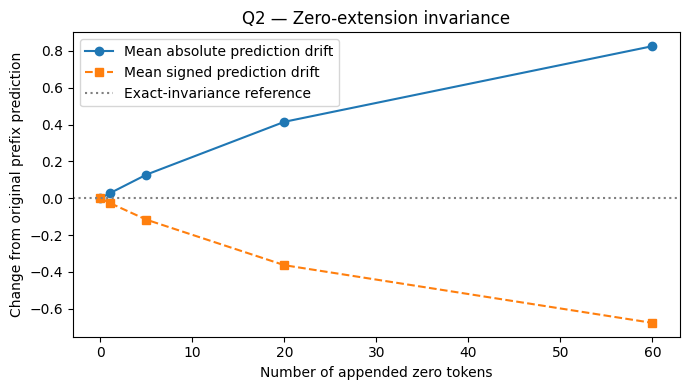

In [6]:
# Visualise the results
tail_lengths = [
    row["zero_tail_length"]
    for row in q2_results
]

ordinary_drift = [
    row["ordinary"]["absolute_prediction_drift"]
    for row in q2_results
]

signed_drift = [
    row["ordinary"]["signed_prediction_drift"]
    for row in q2_results
]

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    tail_lengths,
    ordinary_drift,
    marker="o",
    label="Mean absolute prediction drift",
)

ax.plot(
    tail_lengths,
    signed_drift,
    marker="s",
    linestyle="--",
    label="Mean signed prediction drift",
)

ax.axhline(
    0,
    color="grey",
    linestyle=":",
    label="Exact-invariance reference",
)

ax.set(
    xlabel="Number of appended zero tokens",
    ylabel="Change from original prefix prediction",
    title="Q2 — Zero-extension invariance",
)

ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## Sampling uncertainty in zero-extension drift

The preceding experiment establishes non-zero prediction drift under controlled zero extensions of $T=20$ prefixes.

We now quantify the variability of this effect across independently sampled prefixes. For prefix $b$, define

$$
d_b(m)=f_\theta(x_b,0^m)-f_\theta(x_b).
$$

Our empirical estimators are

$$
\hat S(m)=\frac1B\sum_{b=1}^{B}d_b(m),
\qquad
\hat D(m)=\frac1B\sum_{b=1}^{B}|d_b(m)|.
$$

For either estimator, the approximate sampling standard error is the sample standard deviation of its per-prefix contributions divided by $\sqrt B$.

We report approximate 95% confidence intervals using $\hat\mu\pm1.96,\widehat{\mathrm{SE}}$. These intervals quantify uncertainty from sampling prefixes, conditional on the fixed trained model. They do not include variation across independently trained GRUs. We additionally verify that our per-prefix calculations reproduce the aggregate drift statistics returned by `zero_tail_drift()`.

In [7]:
import math

@torch.no_grad()
def paired_zero_drifts(model, prefix, tail_lengths):
    """Return one prediction drift per prefix and tail length."""
    prefix = prefix.to(next(model.parameters()))

    _, h_start = model.gru(prefix)
    y_start = model.readout(h_start).squeeze(-1)

    drifts = {}

    for m in tail_lengths:
        tail = prefix.new_zeros((m, prefix.shape[1], 1))
        _, h_end = model.gru(tail, h_start)

        y_end = model.readout(h_end).squeeze(-1)

        drifts[m] = (y_end - y_start).cpu().double()

    return drifts


def mean_ci(values):
    """Normal-approximation CI over independently sampled prefixes."""
    values = values.double()
    n = values.numel()

    mean = values.mean().item()
    se = values.std(unbiased=True).item() / math.sqrt(n)

    return mean, mean - 1.96 * se, mean + 1.96 * se


# Use precisely the same prefixes as the original Q2 experiment.
drifts_20 = paired_zero_drifts(model, prefix, TAIL_LENGTHS)

reference = {
    row["zero_tail_length"]: row["ordinary"]
    for row in q2_results
}

print(" m       S(m)       95% CI for S(m)        D(m)       95% CI for D(m)")

for m, d in drifts_20.items():
    s, s_lo, s_hi = mean_ci(d)
    a, a_lo, a_hi = mean_ci(d.abs())

    # Reconcile against the original implementation.
    assert abs(s - reference[m]["signed_prediction_drift"]) < 1e-6
    assert abs(a - reference[m]["absolute_prediction_drift"]) < 1e-6

    print(
        f"{m:2d}  {s:+10.5f}  [{s_lo:+.5f}, {s_hi:+.5f}]"
        f"  {a:10.5f}  [{a_lo:.5f}, {a_hi:.5f}]"
    )

print("Per-prefix calculations agree with zero_tail_drift().")

 m       S(m)       95% CI for S(m)        D(m)       95% CI for D(m)
 0    +0.00000  [+0.00000, +0.00000]     0.00000  [0.00000, 0.00000]
 1    -0.02521  [-0.02788, -0.02254]     0.02722  [0.02463, 0.02982]
 5    -0.11628  [-0.12823, -0.10433]     0.12870  [0.11724, 0.14016]
20    -0.36335  [-0.39772, -0.32899]     0.41544  [0.38338, 0.44751]
60    -0.67655  [-0.73744, -0.61565]     0.82608  [0.77256, 0.87960]
Per-prefix calculations agree with zero_tail_drift().


## Zero extension invariance within and beyond the training length range

We originally began with prefixes of length $T=20$. Consequently, every positive zero extension crosses the maximum training length.

To determine whether zero-extension non-invariance also occurs at familiar total lengths, we repeat the paired experiment using prefixes of length $T=10$. To do so, we evaluate

$$
m\in\{0,1,5,10,20,60\}.
$$

The first four conditions have total length $T+m\leq20$, while the remaining conditions exceed the training length range.

**note:** These are ID-length extensions, not ordinary ID-distributed samples. Forcing a zero suffix changes the conditional token distribution even when the total sequence length remains familiar.

The two prefix length groups also have different count distributions. We will therefore describe differences between the $T=10$ and $T=20$ experiments rather than attribute them exclusively to the distance from the training boundary. The principal question is whether prediction drift is detectable before the recurrent horizon exceeds the training-length interval.

In [8]:
PREFIX_LENGTH_10 = 10
Q2_INTERIOR_SEED = 2003
TAIL_LENGTHS_10 = (0, 1, 5, 10, 20, 60)

rng_10 = torch.Generator().manual_seed(Q2_INTERIOR_SEED)

prefix_10, target_10, _ = exp.generate_counting_batch(
    T=PREFIX_LENGTH_10,
    batch_size=B_Q2,
    p=0.5,
    device=DEVICE,
    generator=rng_10,
)

# Original experiment function: unchanged.
q2_results_10 = exp.zero_tail_drift(
    model,
    prefix_10,
    tail_lengths=TAIL_LENGTHS_10,
)

# Per-prefix values for comparison and verification.
drifts_10 = paired_zero_drifts(
    model, prefix_10, TAIL_LENGTHS_10
)

print(" m   Total T   Region       Signed drift   Absolute drift   MAE    Accuracy")

for row in q2_results_10:
    m = row["zero_tail_length"]
    total_T = PREFIX_LENGTH_10 + m
    region = "ID-length" if total_T <= 20 else "OOD-length"

    ordinary = row["ordinary"]
    d = drifts_10[m]

    assert abs(
        d.mean().item() - ordinary["signed_prediction_drift"]
    ) < 1e-6

    assert abs(
        d.abs().mean().item() - ordinary["absolute_prediction_drift"]
    ) < 1e-6

    assert row["clamped"]["absolute_prediction_drift"] == 0.0
    assert row["clamped"]["hidden_displacement"] == 0.0

    print(
        f"{m:2d} {total_T:9d} {region:>11}"
        f" {ordinary['signed_prediction_drift']:+14.5f}"
        f" {ordinary['absolute_prediction_drift']:15.5f}"
        f" {ordinary['mae']:7.4f}"
        f" {ordinary['rounded_accuracy']:9.3f}"
    )

 m   Total T   Region       Signed drift   Absolute drift   MAE    Accuracy
 0        10   ID-length       +0.00000         0.00000  0.0436     1.000
 1        11   ID-length       -0.01194         0.01200  0.0526     1.000
 5        15   ID-length       -0.04626         0.04775  0.0846     1.000
10        20   ID-length       -0.07911         0.08471  0.1189     1.000
20        30  OOD-length       -0.14107         0.15781  0.1900     1.000
60        70  OOD-length       -0.39396         0.45767  0.4897     0.425


## Heterogeneity across prefix states

The Q2a results show that mean absolute drift exceeds the magnitude of mean signed drift:

$$
D(m)>|S(m)|.
$$

This establishes that positive and negative drift contributions coexist, but does not establish how many prefixes exhibit each sign. We therefore directly estimate

$$
P(\Delta_m>0),\qquad
P(\Delta_m<0),\qquad
P(\Delta_m=0).
$$

Next, we condition drift on the true prefix count

$$
K=\sum_{t=1}^{20}X_t.
$$

Our conditional statistic is

$$
\boxed{
S(m\mid K=k)=
\mathbb E[\Delta_m(X)\mid K=k].
}
$$

This identifies whether the response to appended zeros differs systematically across prefixes containing different numbers of ones.

We retain the original $T=20$ prefixes and inspect $m=20$ and $m=60$.

Count groups containing fewer than 20 sampled examples will be reported but excluded from the principal conditional plot (to avoid giving visually disproportionate weight to poorly sampled tail counts).

In [9]:
# Part A: Direction of drift
print(" m    P(d<0)    P(d>0)    P(d=0)")

for m, d in drifts_20.items():
    if m == 0:
        continue

    n_neg = (d < 0).sum().item()
    n_pos = (d > 0).sum().item()
    n_zero = (d == 0).sum().item()

    n = d.numel()
    assert n_neg + n_pos + n_zero == n

    print(
        f"{m:2d}  {n_neg/n:8.3f}"
        f"  {n_pos/n:8.3f}"
        f"  {n_zero/n:8.3f}"
    )


# Part B: Drift conditional on true prefix count
prefix_counts = target.detach().cpu().long()

conditional_rows = []

print("\n m   Count   n    Mean drift       SE        Note")

for m in (20, 60):
    d = drifts_20[m]

    for k in prefix_counts.unique(sorted=True).tolist():
        mask = prefix_counts == k
        values = d[mask]
        n = values.numel()

        mean = values.mean().item()
        se = (
            values.std(unbiased=True).item() / math.sqrt(n)
            if n > 1 else float("nan")
        )

        conditional_rows.append({
            "m": m,
            "count": k,
            "n": n,
            "mean": mean,
            "se": se,
        })

        note = "[few samples]" if n < 20 else ""

        print(
            f"{m:2d} {k:7d} {n:4d}"
            f" {mean:+12.5f} {se:9.5f}    {note}"
        )

 m    P(d<0)    P(d>0)    P(d=0)
 1     0.690     0.310     0.000
 5     0.661     0.339     0.000
20     0.651     0.349     0.000
60     0.651     0.349     0.000

 m   Count   n    Mean drift       SE        Note
20       3    2     -0.24211   0.00106    [few samples]
20       4    9     -0.24608   0.00296    [few samples]
20       5    9     -0.18366   0.00264    [few samples]
20       6   35     -0.07099   0.00119    
20       7   66     +0.04415   0.00096    
20       8  124     +0.10616   0.00035    
20       9  167     +0.06342   0.00020    
20      10  199     -0.11098   0.00052    
20      11  153     -0.40787   0.00094    
20      12  127     -0.79190   0.00215    
20      13   71     -1.22965   0.00537    
20      14   39     -1.68793   0.01164    
20      15   11     -2.08073   0.03692    [few samples]
20      16   11     -2.51927   0.02219    [few samples]
20      18    1     -3.11364       nan    [few samples]
60       3    2     -0.66145   0.00406    [few samples]
60   

In [10]:
# Check whether positive drift is confined to counts 7–9
k = target.detach().cpu().long()
positive_band = (k >= 7) & (k <= 9)

for m in (20, 60):
    actual_positive = drifts_20[m] > 0

    mismatches = (actual_positive != positive_band).sum().item()

    print(f"m={m}: sign/count-band mismatches = {mismatches}")

m=20: sign/count-band mismatches = 0
m=60: sign/count-band mismatches = 0


### Observations

So it indeed looks like, within this sampled prefix collection, the sign of the zero-extension drift at both tail length is determined by whether the true prefix count belongs to counts 7-9.

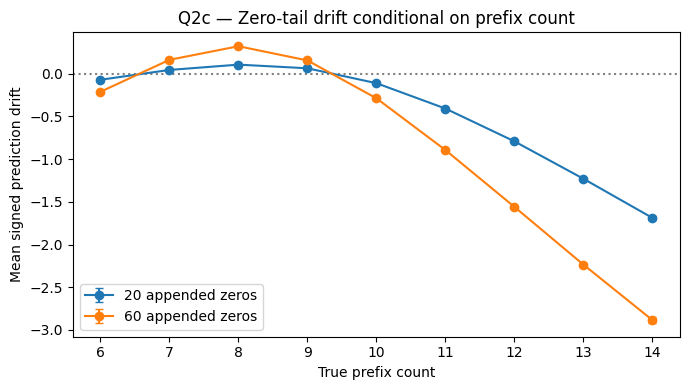

In [27]:
fig, ax = plt.subplots(figsize=(7, 4))

for m in (20, 60):
    rows = [
        row for row in conditional_rows
        if row["m"] == m and row["n"] >= 20
    ]

    ax.errorbar(
        [row["count"] for row in rows],
        [row["mean"] for row in rows],
        yerr=[1.96 * row["se"] for row in rows],
        marker="o",
        capsize=3,
        label=f"{m} appended zeros",
    )

ax.axhline(0, color="grey", linestyle=":")

ax.set(
    xlabel="True prefix count",
    ylabel="Mean signed prediction drift",
    title="Q2c — Zero-tail drift conditional on prefix count",
)

ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

Q2 clearly shows that the trained GRU violates zero-extension invariance. Interestingly, this is true even when the extended sequence length remains *within* the training interval. Exact functional invariance is likely a strict requirement.

Under the sampled $T=20$ prefix distribution, the zero-extension prediction drift is overwhelmingly associated with the true prefix count, with comparatively little variation among sampled prefixes sharing the same count.

Within the sampled count groups, prediction drift varies relatively little compared with its differences between count groups.

The non-monotonic drift appears to rule out several competing explanations based on a length only response or uniform forgetting. But any statement about the exact internal recurrent mechanism is obviously not conclusive from Q2. Much more needs to be understand about the counter that the hidden state contains, for example, and whether that information is erased. Another question: could the predictor be invariant to permutations? Why?
